In [ ]:
import numpy as np
import astropy.units as u
from astropy.io import fits 
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from astropy.table import Table
import glob
from pathlib import Path

plt.rcParams.update({
#"text.usetex": True,
'axes.labelsize' : 16,
'xtick.labelsize' : 14,
'ytick.labelsize' : 14,
'xtick.direction' : "in",
'ytick.direction' : "in",
'xtick.top' : True,
'ytick.right' : True,
"xtick.minor.visible" : False,
"ytick.minor.visible" : False,
"font.family" : "serif"})

In [89]:
oceans_targets_cat = Table.read(r"C:\Users\madpb\Documents\OCEANS\OCEANS_target_catalog.fits")
data_direc = Path(r"C:\Users\madpb\Documents\OCEANS\MB Subracted Reductions\v0.3\x1d")
save_direc = Path(r"C:\Users\madpb\Documents\OCEANS\MB Subracted Reductions\v0.3\combined_x1d")

median_diffs = []

## loop through 6 OCEANS pointings 
for pointing_num in range(1, 7):
    col_name = f"in_{pointing_num}"
    for source in oceans_targets_cat:
        # only grab sources in the current pointing
        if source[col_name] == 1:
            ## get source id 
            source_id = str(source["OCEANS_APT_ID"][0].decode("utf-8")).zfill(9)
            #print(source_id)
    
            # Build search paths using pathlib
            p_dir = f"P{pointing_num}"
            file_235 = glob.glob(str(data_direc / p_dir / f"*_g235h_s{source_id}*.fits"))
            file_395 = glob.glob(str(data_direc / p_dir / f"*_g395h_s{source_id}*.fits"))

            # Ensure both filter files were found
            if not file_235 or not file_395:
                continue
            comb_fits, median_diff = combine_filters(file_235[0], file_395[0], source_id, plot_spec=False)

            ## save median differences 
            median_diffs.append(median_diff)

            # Define output destination and write
            out_dir = save_direc / p_dir
            out_dir.mkdir(parents=True, exist_ok=True)  # Create P1..P6 subfolders if missing
            
            outname = out_dir / f"s{source_id}_x1d_combgrat.fits"
            comb_fits.writeto(outname, overwrite=True)

C:\Users\madpb\AppData\Local\Temp\ipykernel_40300\276292234.py:77: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)


Text(0, 0.5, 'Number')

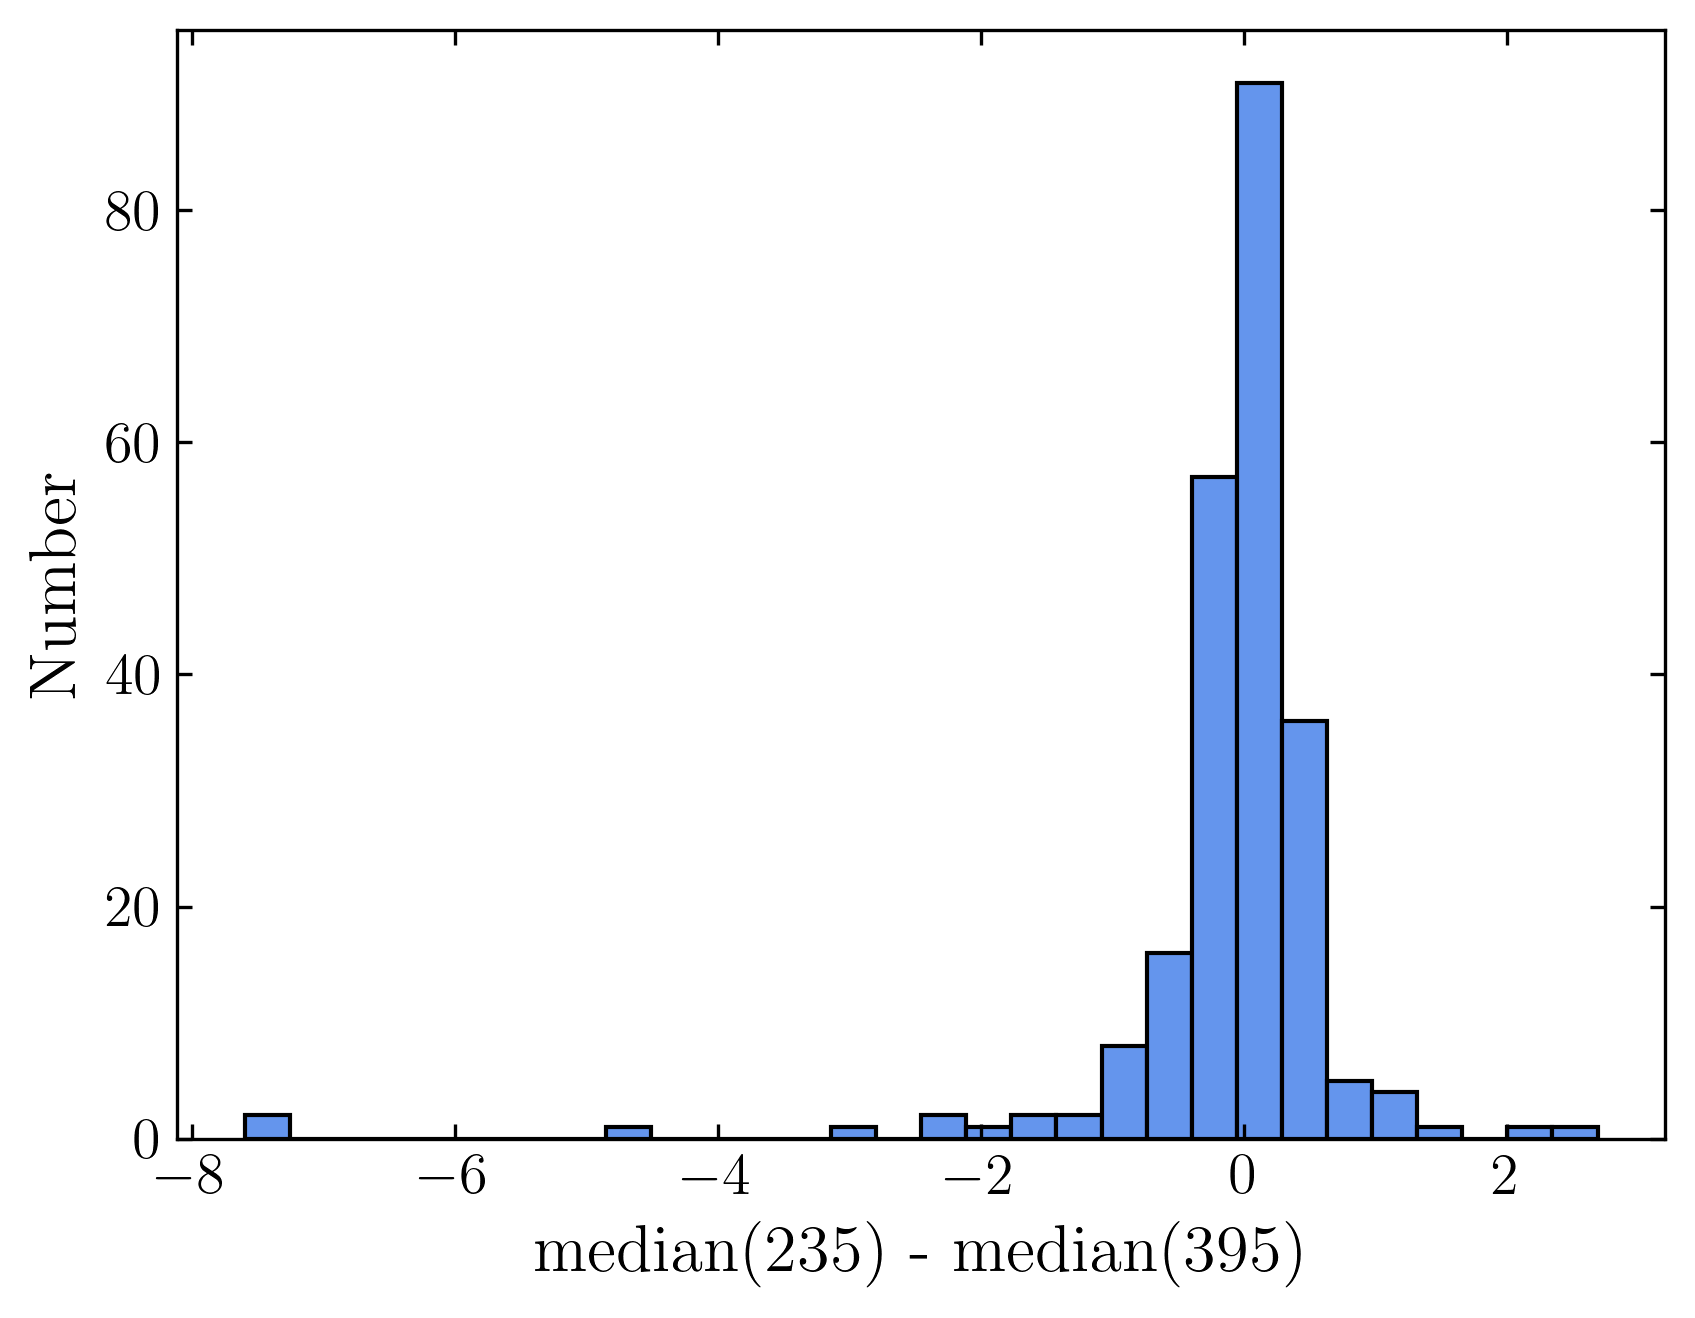

In [25]:
plt.figure(dpi = 300)
plt.hist(np.array(median_diffs) * 1e30, bins = 30,
        color = "cornflowerblue", edgecolor = "black")
plt.xlabel("median(235) - median(395)")
plt.ylabel("Number")

C:\Users\madpb\Documents\OCEANS\MB Subracted Reductions\v0.3\combined_x1d\P1\s000148165_x1d_combgrat.fits


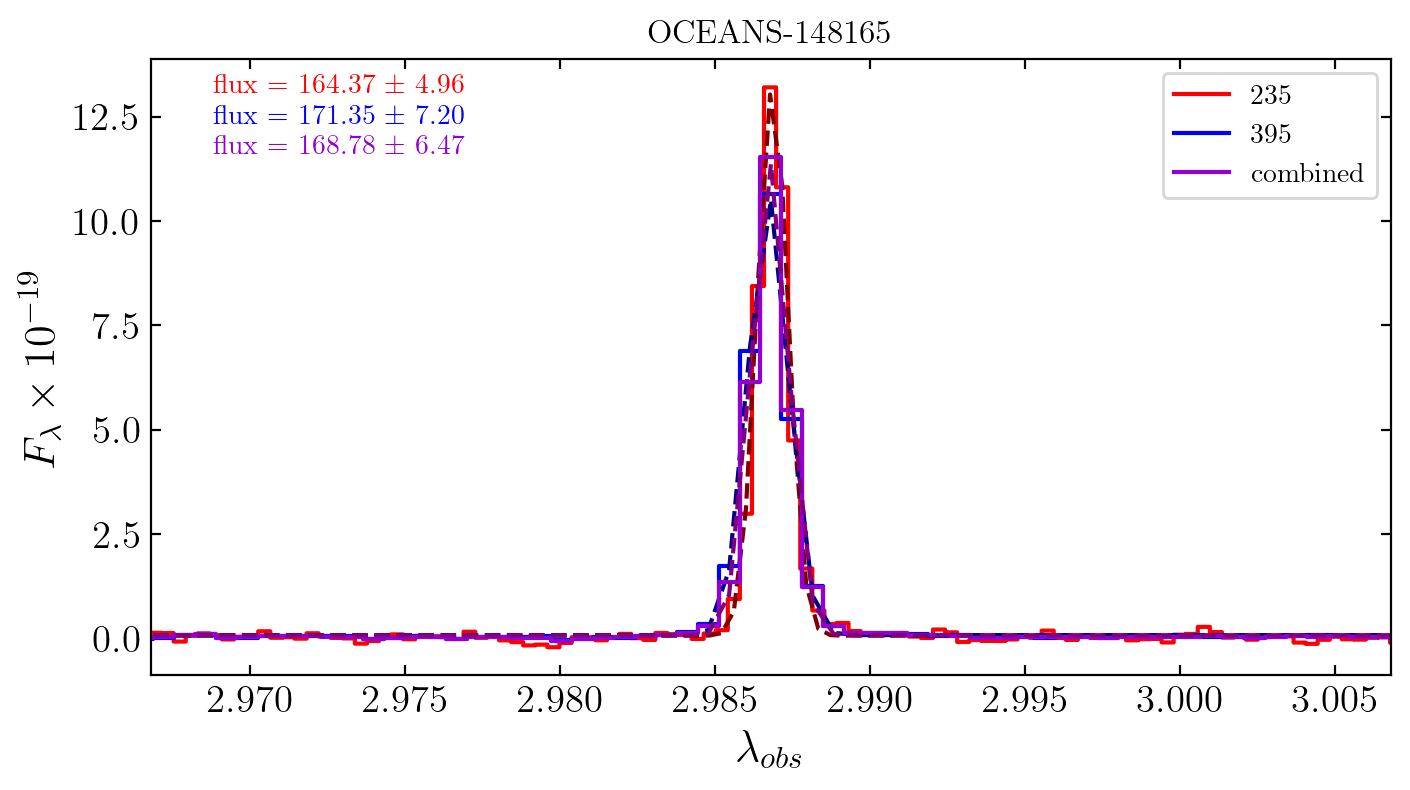

C:\Users\madpb\Documents\OCEANS\MB Subracted Reductions\v0.3\combined_x1d\P1\s000025277_x1d_combgrat.fits


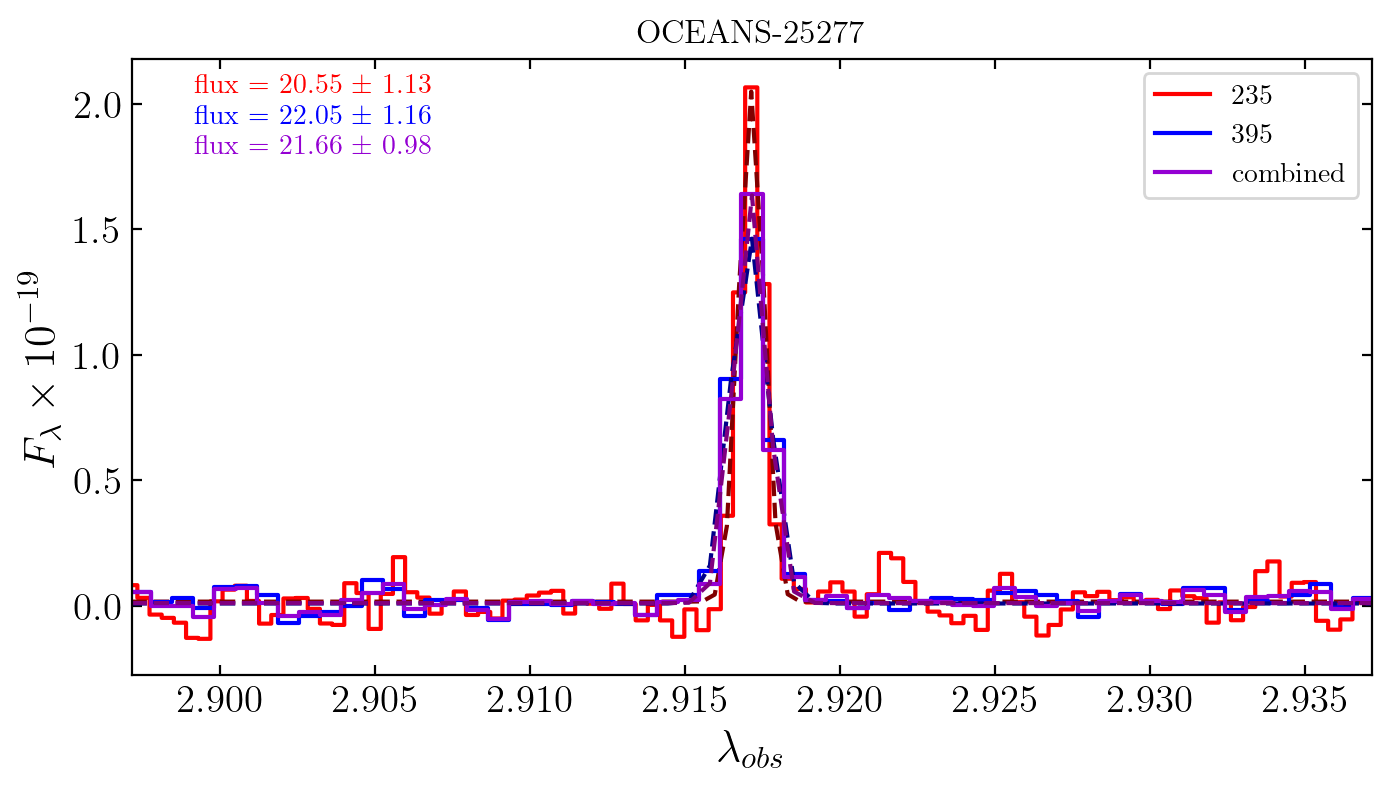

C:\Users\madpb\Documents\OCEANS\MB Subracted Reductions\v0.3\combined_x1d\P3\s000019175_x1d_combgrat.fits


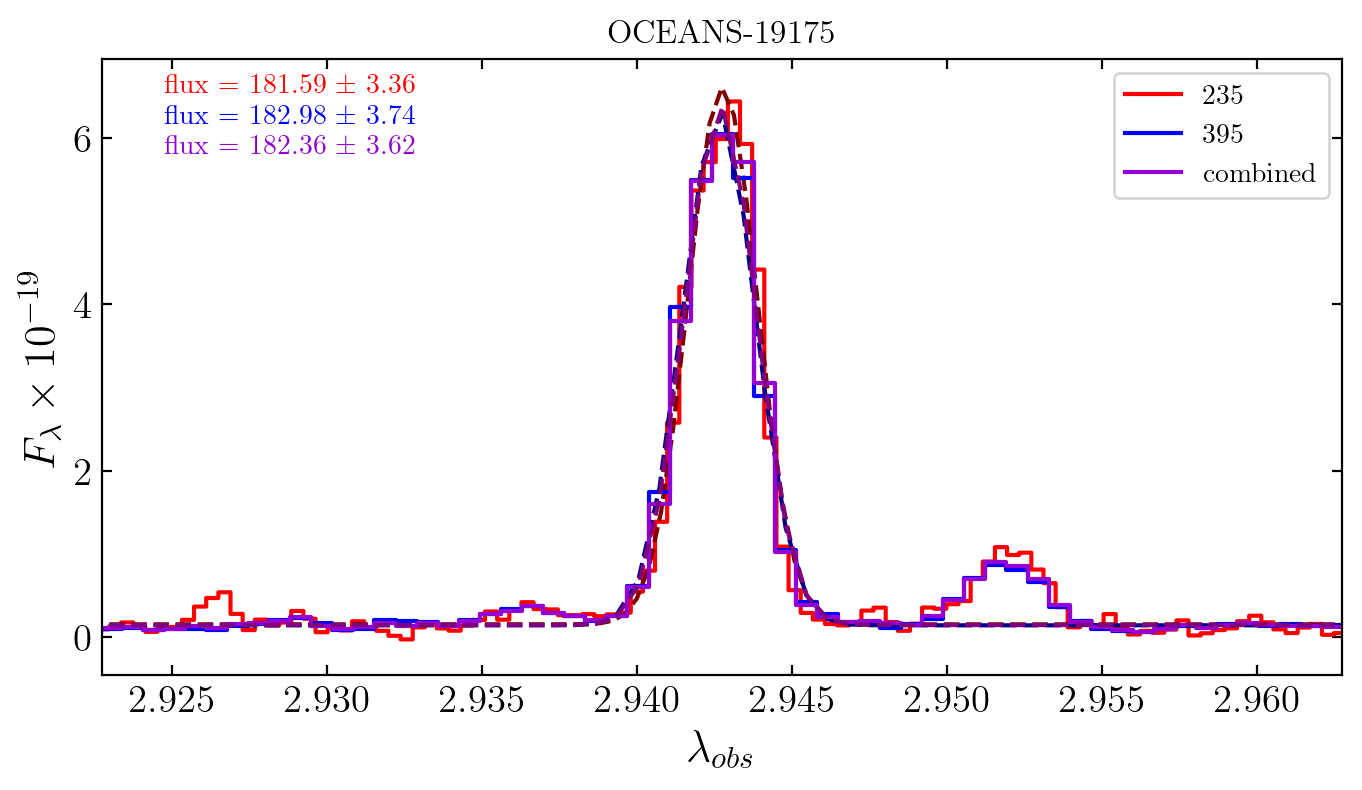

In [87]:
from astropy.modeling import models, fitting
## opening up source 0148165, 25277, 19175, 148738 to see if flux is conserved post combined grating
ids_find = [148165, 25277, 19175]

for source in ids_find:
    source_id = str(source).zfill(9)

    file_235 = glob.glob(str(data_direc / "*" / f"*_g235h_s{source_id}*.fits"))
    file_395 = glob.glob(str(data_direc / "*" / f"*_g395h_s{source_id}*.fits"))
    file_comb_spec = glob.glob(str(save_direc / "*" / f"s{source_id}*.fits"))
    
    wv_235, fnu_235, fnu_err_235, flam_235, flam_err_235 = load_1d_spec(file_235[0])
    wv_395, fnu_395, fnu_err_395, flam_395, flam_err_395 = load_1d_spec(file_395[0])
    wv_comb, fnu_comb, fnu_err_comb, fnu_lam_comb, fnu_err_comb = load_1d_spec(file_comb_spec[0])
    print(file_comb_spec[0])

    ## removing units 
    wv_235, fnu_235, fnu_err_235, flam_235, flam_err_235 = wv_235.value, fnu_235.value, fnu_err_235.value, flam_235.value, flam_err_235.value
    wv_395, fnu_395, fnu_err_395, flam_395, flam_err_395 = wv_395.value, fnu_395.value, fnu_err_395.value, flam_395.value, flam_err_395.value
    wv_comb, fnu_comb, fnu_err_comb, flam_comb, fnu_err_comb = wv_comb.value, fnu_comb.value, fnu_err_comb.value, fnu_lam_comb.value, fnu_err_comb.value


    ## find overlap between 235 and 395 wavelengths
    min_wv_235, max_wv_235 = np.nanmin(wv_235), np.nanmax(wv_235)
    min_wv_395, max_wv_395 = np.nanmin(wv_395), np.nanmax(wv_395)

    ## minumum and maxium wavelenghts of the overlapping region
    overlapping_min = max(min_wv_235, min_wv_395)
    overlapping_max = min(max_wv_235, max_wv_395)

    mask_235 = (wv_235 >= overlapping_min) & (wv_235 <= overlapping_max)
    mask_395 = (wv_395 >= overlapping_min) & (wv_395 <= overlapping_max)
    mask_comb = (wv_comb >= overlapping_min) & (wv_comb <= overlapping_max)

    ## lets find the peak of the data for each file, and fit a single Gaussian to that emission line 
    peak_index = np.nanargmax(flam_comb[mask_comb])
    wv_max = wv_comb[mask_comb][peak_index]

    fitter = fitting.LevMarLSQFitter(calc_uncertainties=True) ## least-squares fitting is the most common method 

    g_init_narrow = models.Gaussian1D(amplitude = 5, mean = wv_max, stddev = .01)
    g_init_constant = models.Const1D(0) ## we add a constant model because of the continuum light from the galaxy, its sort of like a "base line"
    g_init = g_init_narrow + g_init_constant

    fitted_model_235 = fitter(g_init, wv_235[mask_235], flam_235[mask_235] * 1e19, filter_non_finite=True)
    fitted_model_395 = fitter(g_init, wv_395[mask_395], flam_395[mask_395] * 1e19, filter_non_finite=True)
    fitted_model_comb = fitter(g_init, wv_comb[mask_comb], flam_comb[mask_comb] * 1e19, filter_non_finite=True)
    #print(wv_235[mask_235], flam_235[mask_235] * 1e19)


    plt.figure(figsize = [8,4], dpi = 200)
    plt.plot(wv_235[mask_235], flam_235[mask_235] * 1e19, drawstyle = "steps-mid", color = "red", label = "235")
    plt.plot(wv_235[mask_235], fitted_model_235(wv_235[mask_235]), linestyle = "--", color = "maroon")
    amp = fitted_model_235.amplitude_0
    stddev = fitted_model_235.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)
    # --- flux error propagation ---
    amp_err = fitted_model_235.stds.stds[fitted_model_235.param_names.index('amplitude_0')]
    stddev_err = fitted_model_235.stds.stds[fitted_model_235.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.95, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "red",
             transform=ax.transAxes)

    
    plt.plot(wv_395[mask_395], flam_395[mask_395] * 1e19, drawstyle = "steps-mid", color = "blue", label = "395")
    plt.plot(wv_395[mask_395], fitted_model_395(wv_395[mask_395]), linestyle = "--", color = "darkblue")
    amp = fitted_model_395.amplitude_0
    stddev = fitted_model_395.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)

    # --- flux error propagation ---
    amp_err = fitted_model_395.stds.stds[fitted_model_395.param_names.index('amplitude_0')]
    stddev_err = fitted_model_395.stds.stds[fitted_model_395.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.9, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "blue",
             transform=ax.transAxes)
    
    
    plt.plot(wv_comb[mask_comb], flam_comb[mask_comb] * 1e19, drawstyle = "steps-mid", color = "darkviolet", label = "combined")
    plt.plot(wv_comb[mask_comb], fitted_model_comb(wv_comb[mask_comb]), linestyle = "--", color = "purple")
    amp = fitted_model_comb.amplitude_0
    stddev = fitted_model_comb.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)

    # --- flux error propagation ---
    amp_err = fitted_model_comb.stds.stds[fitted_model_comb.param_names.index('amplitude_0')]
    stddev_err = fitted_model_comb.stds.stds[fitted_model_comb.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.85, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "darkviolet",
             transform=ax.transAxes)

    plt.xlim(wv_max - .02, wv_max + .02)
    plt.ylabel(r"$F_{\lambda} \times 10^{-19}$")
    plt.xlabel(r"$\lambda_{obs}$")
    plt.title(f"OCEANS-{source}")
    
    plt.legend()
    plt.show()